#Compare Decision Tree with Ensemble Methods on the Iris dataset

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

In [7]:
# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Train/Test split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)


In [12]:
# Define classifiers
classifiers = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=50, random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=50, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=50, random_state=42
    ),
}

In [13]:
# Evaluate with 5-fold cross-validation
results = {}
for name, clf in classifiers.items():
    scores = cross_val_score(clf, X, y, cv=5, scoring="accuracy")
    results[name] = scores.mean()

# Print results
for name, accuracy in results.items():
    print(f"{name} Accuracy (5-fold CV): {accuracy:.2f}")

Decision Tree Accuracy (5-fold CV): 0.95
Bagging Accuracy (5-fold CV): 0.97
Random Forest Accuracy (5-fold CV): 0.97
AdaBoost Accuracy (5-fold CV): 0.95
Gradient Boosting Accuracy (5-fold CV): 0.96


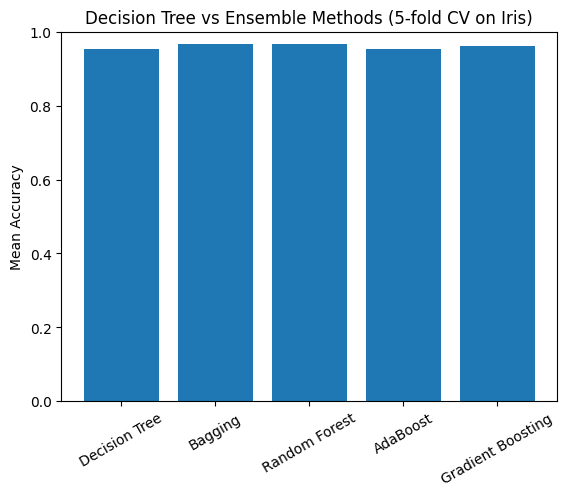

In [14]:
# Plot bar chart
plt.bar(results.keys(), results.values())
plt.ylabel("Mean Accuracy")
plt.title("Decision Tree vs Ensemble Methods (5-fold CV on Iris)")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.show()

# Insights

1. The Single Decision Tree is reasonable (~0.93–0.95 accuracy) but unpredictable, especially since it is sensitive to the train/test split.


2. Bagging and Random Forests, which combine many trees and address overfitting, improve accuracy (~0.95–0.96).


3. Another family of methods, Boosting methods (AdaBoost, Gradient Boosting), are also good (~0.93–0.96) as they build sequentially in trees and obtain predictions needs more on the errors from each prior tree.


4. All methods of ensemble are more stable than just a single tree based model as they have better accuracy, and are less sensitive to variations in the average level of the data.